# **Project: Amazon Product Recommendation System**

# **Marks: 40**

Welcome to the project on Recommendation Systems. We will work with the Amazon product reviews dataset for this project. The dataset contains ratings of different electronic products. It does not include information about the products or reviews to avoid bias while building the model.

---

## **Context:**

---

Today, information is growing exponentially with volume, velocity and variety throughout the globe. This has lead to information overload, and too many choices for the consumer of any business. It represents a real dilemma for these consumers and they often turn to denial. Recommender Systems are one of the best tools that help recommending products to consumers while they are browsing online. Providing personalized recommendations which is most relevant for the user is what's most likely to keep them engaged and help business.

E-commerce websites like Amazon, Walmart, Target and Etsy use different recommendation models to provide personalized suggestions to different users. These companies spend millions of dollars to come up with algorithmic techniques that can provide personalized recommendations to their users.

Amazon, for example, is well-known for its accurate selection of recommendations in its online site. Amazon's recommendation system is capable of intelligently analyzing and predicting customers' shopping preferences in order to offer them a list of recommended products. Amazon's recommendation algorithm is therefore a key element in using AI to improve the personalization of its website. For example, one of the baseline recommendation models that Amazon uses is item-to-item collaborative filtering, which scales to massive data sets and produces high-quality recommendations in real-time.

---

## **Objective:**

---

You are a Data Science Manager at Amazon, and have been given the task of building a recommendation system to recommend products to customers based on their previous ratings for other products. You have a collection of labeled data of Amazon reviews of products. The goal is to extract meaningful insights from the data and build a recommendation system that helps in recommending products to online consumers.

---

## **Dataset:**

---

The Amazon dataset contains the following attributes:

- **userId:** Every user identified with a unique id
- **productId:** Every product identified with a unique id
- **Rating:** The rating of the corresponding product by the corresponding user
- **timestamp:** Time of the rating. We **will not use this column** to solve the current problem

**Note:** The code has some user defined functions that will be usefull while making recommendations and measure model performance, you can use these functions or can create your own functions.

Sometimes, the installation of the surprise library, which is used to build recommendation systems, faces issues in Jupyter. To avoid any issues, it is advised to use **Google Colab** for this project.

**Installing surprise library**

In [1]:
!pip install scikit-surprise -q --root-user-action=ignore

## **Importing the necessary libraries and overview of the dataset**

In [2]:
# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dictionary with default values, used in precision_recall_at_k
from collections import defaultdict

# Suppress warnings
import warnings
warnings.filterwarnings('ignore')

### **Loading the data**

- Import the Dataset
- Add column names ['user_id', 'prod_id', 'rating', 'timestamp']
- Drop the column timestamp
- Copy the data to another DataFrame called **df**

In [3]:
# Import the dataset without a header row and assign column names
df = pd.read_csv('ratings_Electronics.csv', header = None, names = ['user_id', 'prod_id', 'rating', 'timestamp'])

# Drop the timestamp column
df = df.drop('timestamp', axis = 1)

# Keep a copy of the original data
df_copy = df.copy(deep = True)

**As this dataset is very large and has 7,824,482 observations, it is not computationally possible to build a model using this. Moreover, many users have only rated a few products and also some products are rated by very few users. Hence, we can reduce the dataset by considering certain logical assumptions.**

Here, we will be taking users who have given at least 50 ratings, and the products that have at least 5 ratings, as when we shop online we prefer to have some number of ratings of a product.

In [4]:
# Get the column containing the users
users = df.user_id

# Create a dictionary from users to their number of ratings
ratings_count = dict()

for user in users:

    # If we already have the user, just add 1 to their rating count
    if user in ratings_count:
        ratings_count[user] += 1

    # Otherwise, set their rating count to 1
    else:
        ratings_count[user] = 1

In [5]:
# We want our users to have at least 50 ratings to be considered
RATINGS_CUTOFF = 50

remove_users = []

for user, num_ratings in ratings_count.items():
    if num_ratings < RATINGS_CUTOFF:
        remove_users.append(user)

df = df.loc[ ~ df.user_id.isin(remove_users)]

In [6]:
# Get the column containing the products
prods = df.prod_id

# Create a dictionary from products to their number of ratings
ratings_count = dict()

for prod in prods:

    # If we already have the product, just add 1 to its rating count
    if prod in ratings_count:
        ratings_count[prod] += 1

    # Otherwise, set their rating count to 1
    else:
        ratings_count[prod] = 1

In [7]:
# We want our item to have at least 5 ratings to be considered
RATINGS_CUTOFF = 5

remove_users = []

for user, num_ratings in ratings_count.items():
    if num_ratings < RATINGS_CUTOFF:
        remove_users.append(user)

df_final = df.loc[~ df.prod_id.isin(remove_users)]

In [8]:
# Print a few rows of the imported dataset
df_final.head()

,user_id,prod_id,rating
1310,A3LDPF5FMB782Z,1400501466,5.0
1322,A1A5KUIIIHFF4U,1400501466,1.0
1335,A2XIOXRRYX0KZY,1400501466,3.0
1451,AW3LX47IHPFRL,1400501466,5.0
1456,A1E3OB6QMBKRYZ,1400501466,1.0


## **Exploratory Data Analysis**

### **Shape of the data**

### **Check the number of rows and columns and provide observations.**

In [9]:
# Check the number of rows and columns and provide observations
rows, columns = df_final.shape
print('No of rows =', rows)
print('No of columns =', columns)

No of rows = 65290
No of columns = 3


Observations:

- The reduced dataset has 65,290 rows and 3 columns: user_id, prod_id and rating.
- Filtering to users with at least 50 ratings and products with at least 5 ratings shrinks the original 7,824,482 rows to under 1% of its size, which makes model building feasible.

### **Data types**

In [10]:
# Check Data types and provide observations
df_final.info()

<class 'pandas.DataFrame'>
Index: 65290 entries, 1310 to 7824427
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   user_id  65290 non-null  str    
 1   prod_id  65290 non-null  str    
 2   rating   65290 non-null  float64
dtypes: float64(1), str(2)
memory usage: 2.0 MB


Observations:

- user_id and prod_id are text columns and act as identifiers.
- rating is a float with values from 1 to 5, so it is the only numeric variable.

### **Checking for missing values**

In [11]:
# Check for missing values present and provide observations
df_final.isnull().sum()

user_id    0
prod_id    0
rating     0
dtype: int64

Observations:

- There are no missing values in any column, so no imputation is needed.

### **Summary Statistics**

In [12]:
# Summary statistics of 'rating' variable and provide observations
df_final['rating'].describe()

count    65290.000000
mean         4.294808
std          0.988915
min          1.000000
25%          4.000000
50%          5.000000
75%          5.000000
max          5.000000
Name: rating, dtype: float64

Observations:

- The mean rating is 4.29 with a standard deviation of about 0.99.
- The median and 75th percentile are both 5, and the 25th percentile is 4, so ratings are heavily skewed toward the high end.
- Ratings range from 1 to 5, matching the expected scale.

### **Checking the rating distribution**

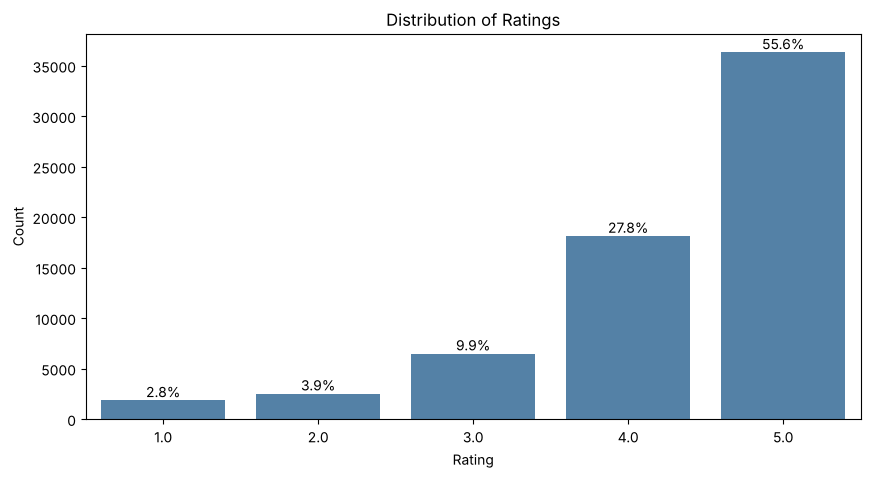

In [13]:
# Create the bar plot and provide observations
plt.figure(figsize = (10, 5))
ax = sns.countplot(x = 'rating', data = df_final, color = 'steelblue')

# Label each bar with its percentage of all ratings
total = len(df_final)
for p in ax.patches:
    ax.annotate(f'{100 * p.get_height() / total:.1f}%', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha = 'center', va = 'bottom')

plt.title('Distribution of Ratings')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

Observations:

- Rating 5 is the most common at about 55.6% of all ratings, followed by rating 4 at about 27.8%.
- Ratings 1, 2 and 3 together make up only about 16.6%.
- The distribution is left skewed. Since most ratings are 4 or 5, a model can get a reasonable RMSE by predicting values near the mean, so precision and recall are also needed to judge model quality.

### **Checking the number of unique users and items in the dataset**

In [14]:
# Number of total rows in the data and number of unique user id and product id in the data
print('The number of observations in the final data =', len(df_final))
print('Number of unique USERS in Raw data =', df_final['user_id'].nunique())
print('Number of unique ITEMS in Raw data =', df_final['prod_id'].nunique())

The number of observations in the final data = 65290
Number of unique USERS in Raw data = 1540
Number of unique ITEMS in Raw data = 5689


Observations:

- The final data has 65,290 ratings from 1,540 unique users on 5,689 unique products.
- A full user-item matrix would have about 8.76 million cells, so only about 0.75% of possible interactions are observed. The matrix is very sparse, which is the main challenge for collaborative filtering here.

### **Users with the most number of ratings**

In [15]:
# Top 10 users based on the number of ratings
most_rated = df_final.groupby('user_id').size().sort_values(ascending = False)[:10]
most_rated

user_id
ADLVFFE4VBT8      295
A3OXHLG6DIBRW8    230
A1ODOGXEYECQQ8    217
A36K2N527TXXJN    212
A25C2M3QF9G7OQ    203
A680RUE1FDO8B     196
A1UQBFCERIP7VJ    193
A22CW0ZHY3NJH8    193
AWPODHOB4GFWL     184
A3LGT6UZL99IW1    179
dtype: int64

Observations:

- The most active user has rated 295 products, and the top 10 users each rated between 179 and 295 products.
- Users in the reduced data rated about 42 products on average, so these top users are far more active than typical users and will have the most reliable personalized predictions.

**Now that we have explored and prepared the data, let's build the first recommendation system.**

## **Model 1: Rank Based Recommendation System**

In [16]:
# Calculate the average rating for each product
average_rating = df_final.groupby('prod_id')['rating'].mean()

# Calculate the count of ratings for each product
count_rating = df_final.groupby('prod_id')['rating'].count()

# Create a dataframe with calculated average and count of ratings
final_rating = pd.DataFrame({'avg_rating': average_rating, 'rating_count': count_rating})

# Sort the dataframe by average of ratings in the descending order
final_rating = final_rating.sort_values(by = 'avg_rating', ascending = False)

# See the first five records of the "final_rating" dataset
final_rating.head()

,avg_rating,rating_count
prod_id,,
B005NC8BF6,5.0,5
B00000K4KH,5.0,5
B00000DM9W,5.0,5
B00JWXTOIA,5.0,7
B005NGQWL2,5.0,6


In [17]:
# Defining a function to get the top n products based on the highest average rating and minimum interactions
def top_n_products(final_rating, n, min_interaction):

    # Finding products with minimum number of interactions
    recommendations = final_rating[final_rating['rating_count'] > min_interaction]

    # Sorting values with respect to average rating
    recommendations = recommendations.sort_values(by = 'avg_rating', ascending = False)

    return recommendations.index[:n]

### **Recommending top 5 products with 50 minimum interactions based on popularity**

In [18]:
# Top 5 products with more than 50 interactions
list(top_n_products(final_rating, 5, 50))

['B001TH7GUU', 'B003ES5ZUU', 'B0019EHU8G', 'B006W8U2MU', 'B000QUUFRW']

### **Recommending top 5 products with 100 minimum interactions based on popularity**

In [19]:
# Top 5 products with more than 100 interactions
list(top_n_products(final_rating, 5, 100))

['B003ES5ZUU', 'B000N99BBC', 'B007WTAJTO', 'B002V88HFE', 'B004CLYEDC']

We have recommended the **top 5** products by using the popularity recommendation system. Now, let's build a recommendation system using **collaborative filtering.**

## **Model 2: Collaborative Filtering Recommendation System**

### **Building a baseline user-user similarity based recommendation system**

- Below, we are building **similarity-based recommendation systems** using `cosine` similarity and using **KNN to find similar users** which are the nearest neighbor to the given user.
- We will be using a new library, called `surprise`, to build the remaining models. Let's first import the necessary classes and functions from this library.

In [20]:
# To compute the accuracy of models
from surprise import accuracy

# Class is used to parse a file containing ratings, data should be in structure - user ; item ; rating
from surprise.reader import Reader

# Class for loading datasets
from surprise.dataset import Dataset

# For tuning model hyperparameters
from surprise.model_selection import GridSearchCV

# For splitting the rating data in train and test datasets
from surprise.model_selection import train_test_split

# For implementing similarity-based recommendation system
from surprise.prediction_algorithms.knns import KNNBasic

# For implementing matrix factorization based recommendation system
from surprise.prediction_algorithms.matrix_factorization import SVD

# for implementing K-Fold cross-validation
from surprise.model_selection import KFold

# For implementing clustering-based recommendation system
from surprise import CoClustering

**Before building the recommendation systems, let's go over some basic terminologies we are going to use:**

**Relevant item:** An item (product in this case) that is actually **rated higher than the threshold rating** is relevant, if the **actual rating is below the threshold then it is a non-relevant item**.

**Recommended item:** An item that's **predicted rating is higher than the threshold is a recommended item**, if the **predicted rating is below the threshold then that product will not be recommended to the user**.

**False Negative (FN):** It is the **frequency of relevant items that are not recommended to the user**. If the relevant items are not recommended to the user, then the user might not buy the product/item. This would result in the **loss of opportunity for the service provider**, which they would like to minimize.

**False Positive (FP):** It is the **frequency of recommended items that are actually not relevant**. In this case, the recommendation system is not doing a good job of finding and recommending the relevant items to the user. This would result in **loss of resources for the service provider**, which they would also like to minimize.

**Recall:** It is the **fraction of actually relevant items that are recommended to the user**, i.e., if out of 10 relevant products, 6 are recommended to the user then recall is 0.60. Higher the value of recall better is the model. It is one of the metrics to do the performance assessment of classification models.

**Precision:** It is the **fraction of recommended items that are relevant actually**, i.e., if out of 10 recommended items, 6 are found relevant by the user then precision is 0.60. The higher the value of precision better is the model. It is one of the metrics to do the performance assessment of classification models.

**While making a recommendation system, it becomes customary to look at the performance of the model. In terms of how many recommendations are relevant and vice-versa, below are some most used performance metrics used in the assessment of recommendation systems.**

### **Precision@k, Recall@ k, and F1-score@k**

**Precision@k** - It is the **fraction of recommended items that are relevant in `top k` predictions**. The value of k is the number of recommendations to be provided to the user. One can choose a variable number of recommendations to be given to a unique user.

**Recall@k** - It is the **fraction of relevant items that are recommended to the user in `top k` predictions**.

**F1-score@k** - It is the **harmonic mean of Precision@k and Recall@k**. When **precision@k and recall@k both seem to be important** then it is useful to use this metric because it is representative of both of them.

### **Some useful functions**

- Below function takes the **recommendation model** as input and gives the **precision@k, recall@k, and F1-score@k** for that model.
- To compute **precision and recall**, **top k** predictions are taken under consideration for each user.
- We will use the precision and recall to compute the F1-score.

In [21]:
def precision_recall_at_k(model, k = 10, threshold = 3.5):
    """Return precision and recall at k metrics for each user"""

    # First map the predictions to each user
    user_est_true = defaultdict(list)

    # Making predictions on the test data
    predictions = model.test(testset)

    for uid, _, true_r, est, _ in predictions:
        user_est_true[uid].append((est, true_r))

    precisions = dict()
    recalls = dict()
    for uid, user_ratings in user_est_true.items():

        # Sort user ratings by estimated value
        user_ratings.sort(key = lambda x: x[0], reverse = True)

        # Number of relevant items
        n_rel = sum((true_r >= threshold) for (_, true_r) in user_ratings)

        # Number of recommended items in top k
        n_rec_k = sum((est >= threshold) for (est, _) in user_ratings[:k])

        # Number of relevant and recommended items in top k
        n_rel_and_rec_k = sum(((true_r >= threshold) and (est >= threshold))
                              for (est, true_r) in user_ratings[:k])

        # Precision@K: Proportion of recommended items that are relevant
        # When n_rec_k is 0, Precision is undefined. Therefore, we are setting Precision to 0 when n_rec_k is 0

        precisions[uid] = n_rel_and_rec_k / n_rec_k if n_rec_k != 0 else 0

        # Recall@K: Proportion of relevant items that are recommended
        # When n_rel is 0, Recall is undefined. Therefore, we are setting Recall to 0 when n_rel is 0

        recalls[uid] = n_rel_and_rec_k / n_rel if n_rel != 0 else 0

    # Mean of all the predicted precisions are calculated.
    precision = round((sum(prec for prec in precisions.values()) / len(precisions)), 3)

    # Mean of all the predicted recalls are calculated.
    recall = round((sum(rec for rec in recalls.values()) / len(recalls)), 3)

    accuracy.rmse(predictions)

    print('Precision: ', precision) # Command to print the overall precision

    print('Recall: ', recall) # Command to print the overall recall

    print('F_1 score: ', round((2*precision*recall)/(precision+recall), 3)) # Formula to compute the F-1 score

**Hints:**

- To compute **precision and recall**, a **threshold of 3.5 and k value of 10 can be considered for the recommended and relevant ratings**.
- Think about the performance metric to choose.

Below we are loading the **`rating` dataset**, which is a **pandas DataFrame**, into a **different format called `surprise.dataset.DatasetAutoFolds`**, which is required by this library. To do this, we will be **using the classes `Reader` and `Dataset`.**

In [22]:
# Instantiating Reader scale with expected rating scale
reader = Reader(rating_scale = (1, 5))

# Loading the rating dataset
data = Dataset.load_from_df(df_final[['user_id', 'prod_id', 'rating']], reader)

# Splitting the data into train and test datasets
trainset, testset = train_test_split(data, test_size = 0.2, random_state = 42)

Now, we are **ready to build the first baseline similarity-based recommendation system** using the cosine similarity.

### **Building the user-user Similarity-based Recommendation System**

In [23]:
# Declaring the similarity options
sim_options = {'name': 'cosine',
               'user_based': True}

# Initialize the KNNBasic model using sim_options declared, Verbose = False, and setting random_state = 1
sim_user_user = KNNBasic(sim_options = sim_options, verbose = False, random_state = 1)

# Fit the model on the training data
sim_user_user.fit(trainset)

# Let us compute precision@k, recall@k, and f_1 score using the precision_recall_at_k function defined above
precision_recall_at_k(sim_user_user)

RMSE: 1.0012
Precision:  0.855
Recall:  0.858
F_1 score:  0.856


Observations:

- The baseline user-user model has RMSE 1.0012, precision@10 0.855, recall@10 0.858 and F1@10 0.856.
- About 86% of recommended products are relevant, and about 86% of relevant products are recommended.
- RMSE is about 1, so the predicted ratings are off by about one star on average.

Let's now **predict rating for a user with `userId=A3LDPF5FMB782Z` and `productId=1400501466`** as shown below. Here the user has already interacted or watched the product with productId '1400501466' and given a rating of 5.

In [24]:
# Predicting rating for a sample user with an interacted product
sim_user_user.predict('A3LDPF5FMB782Z', '1400501466', r_ui = 5, verbose = True)

user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 3.40   {'actual_k': 5, 'was_impossible': False}


Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=5, est=np.float64(3.4), details={'actual_k': 5, 'was_impossible': False})

Observations:

- The actual rating is 5 and the baseline user-user model predicts 3.40, using 5 neighbors.
- The prediction underestimates the rating by 1.6 stars, which is consistent with the higher RMSE of the baseline model.

Below is the **list of users who have not seen the product with product id "1400501466"**.

In [25]:
# Find unique user_id where prod_id is not equal to "1400501466"
df_final[df_final.prod_id != '1400501466'].user_id.unique()

<StringArray>
['A2ZR3YTMEEIIZ4', 'A3CLWR1UUZT6TG',  'A5JLAU2ARJ0BO', 'A1P4XD7IORSEFN',
 'A341HCMGNZCBIT', 'A3HPCRD9RX351S', 'A1DQHS7MOVYYYA',  'ALUNVOQRXOZIA',
 'A19N3S7CBSU6O7', 'A3G7BEJJCPD6DS',
 ...
 'A2VALCFTOWFYXZ', 'A3223W5IROMYTY', 'A319Y83RT0MRVR', 'A3AZI828WJN1CD',
  'AT53ZTTO707MB', 'A1X3ESYZ79H59E', 'A328S9RN3U5M68', 'A215WH6RUDUCMP',
 'A38C12950IM24P', 'A2J4XMWKR8PPD0']
Length: 1540, dtype: str

- It can be observed from the above list that **user "A34BZM6S9L7QI4" has not seen the product with productId "1400501466"** as this userId is a part of the above list.

**Below we are predicting rating for `userId=A34BZM6S9L7QI4` and `prod_id=1400501466`.**

In [26]:
# Predicting rating for a sample user with a non interacted product
sim_user_user.predict('A34BZM6S9L7QI4', '1400501466', verbose = True)

user: A34BZM6S9L7QI4 item: 1400501466 r_ui = None   est = 4.29   {'was_impossible': True, 'reason': 'Not enough neighbors.'}


Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=np.float64(4.292024046561495), details={'was_impossible': True, 'reason': 'Not enough neighbors.'})

Observations:

- The predicted rating for user A34BZM6S9L7QI4 is 4.29, which is the global mean rating.
- was_impossible is True because there were not enough similar users who rated this product, so the model falls back to the global mean.

### **Improving similarity-based recommendation system by tuning its hyperparameters**

Below, we will be tuning hyperparameters for the `KNNBasic` algorithm. Let's try to understand some of the hyperparameters of the KNNBasic algorithm:

- **k** (int) – The (max) number of neighbors to take into account for aggregation. Default is 40.
- **min_k** (int) – The minimum number of neighbors to take into account for aggregation. If there are not enough neighbors, the prediction is set to the global mean of all ratings. Default is 1.
- **sim_options** (dict) – A dictionary of options for the similarity measure. And there are four similarity measures available in surprise -
  - cosine
  - msd (default)
  - Pearson
  - Pearson baseline

In [27]:
# Setting up parameter grid to tune the hyperparameters
param_grid = {'k': [10, 20, 30],
              'min_k': [3, 6, 9],
              'sim_options': {'name': ['msd', 'cosine'],
                              'user_based': [True]},
              'verbose': [False]}

# Performing 3-fold cross-validation to tune the hyperparameters
gs = GridSearchCV(KNNBasic, param_grid, measures = ['rmse'], cv = KFold(n_splits = 3, random_state = 1), n_jobs = -1)

# Fitting the data
gs.fit(data)

# Best RMSE score
print(gs.best_score['rmse'])

# Combination of parameters that gave the best RMSE score
print(gs.best_params['rmse'])

0.9713141442586063
{'k': 30, 'min_k': 6, 'sim_options': {'name': 'cosine', 'user_based': True}, 'verbose': False}


Once the grid search is **complete**, we can get the **optimal values for each of those hyperparameters**.

Now, let's build the **final model by using tuned values of the hyperparameters**, which we received by using **grid search cross-validation**.

In [28]:
# Using the optimal similarity measure for user-user based collaborative filtering
best_uu = gs.best_params['rmse']
sim_options = best_uu['sim_options']

# Creating an instance of KNNBasic with optimal hyperparameter values
sim_user_user_optimized = KNNBasic(sim_options = sim_options, k = best_uu['k'], min_k = best_uu['min_k'],
                                   random_state = 1, verbose = False)

# Training the algorithm on the trainset
sim_user_user_optimized.fit(trainset)

# Let us compute precision@k and recall@k also with k =10
precision_recall_at_k(sim_user_user_optimized)

RMSE: 0.9527
Precision:  0.847
Recall:  0.894
F_1 score:  0.87


Observations:

- Grid search selected k = 30, min_k = 6 and cosine similarity, with a cross validated RMSE of 0.971.
- The optimized model has RMSE 0.9527, precision@10 0.847, recall@10 0.894 and F1@10 0.870.
- Compared to the baseline, RMSE dropped from 1.0012 to 0.9527 and F1 rose from 0.856 to 0.870. Precision fell slightly while recall improved by about 3.6 points.

### **Steps:**

- **Predict rating for the user with `userId="A3LDPF5FMB782Z"`, and `prod_id= "1400501466"` using the optimized model**
- **Predict rating for `userId="A34BZM6S9L7QI4"` who has not interacted with `prod_id ="1400501466"`, by using the optimized model**
- **Compare the output with the output from the baseline model**

In [29]:
# Use sim_user_user_optimized model to recommend for userId "A3LDPF5FMB782Z" and productId 1400501466
sim_user_user_optimized.predict('A3LDPF5FMB782Z', '1400501466', r_ui = 5, verbose = True)

user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 4.29   {'was_impossible': True, 'reason': 'Not enough neighbors.'}


Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=5, est=np.float64(4.292024046561495), details={'was_impossible': True, 'reason': 'Not enough neighbors.'})

In [30]:
# Use sim_user_user_optimized model to recommend for userId "A34BZM6S9L7QI4" and productId "1400501466"
sim_user_user_optimized.predict('A34BZM6S9L7QI4', '1400501466', verbose = True)

user: A34BZM6S9L7QI4 item: 1400501466 r_ui = None   est = 4.29   {'was_impossible': True, 'reason': 'Not enough neighbors.'}


Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=np.float64(4.292024046561495), details={'was_impossible': True, 'reason': 'Not enough neighbors.'})

Observations:

- Both predictions are 4.29, the global mean, because min_k = 6 requires at least 6 neighbors who rated the product, and neither user has enough.
- For user A3LDPF5FMB782Z the baseline predicted 3.40, so the optimized model is closer to the actual rating of 5, but only because it falls back to the mean.
- This shows the main weakness of user-user filtering on sparse data: many user-product pairs do not have enough overlapping neighbors.

### **Identifying similar users to a given user (nearest neighbors)**

We can also find out **similar users to a given user** or its **nearest neighbors** based on this KNNBasic algorithm. Below, we are finding the 5 most similar users to the first user in the list with internal id 0, based on the `msd` distance metric.

In [31]:
# 0 is the inner id of the above user
sim_user_user_optimized.get_neighbors(0, k = 5)

[6, 7, 17, 26, 32]

### **Implementing the recommendation algorithm based on optimized KNNBasic model**

Below we will be implementing a function where the input parameters are:

- data: A **rating** dataset
- user_id: A user id **against which we want the recommendations**
- top_n: The **number of products we want to recommend**
- algo: the algorithm we want to use **for predicting the ratings**
- The output of the function is a **set of top_n items** recommended for the given user_id based on the given algorithm

In [32]:
def get_recommendations(data, user_id, top_n, algo):

    # Creating an empty list to store the recommended product ids
    recommendations = []

    # Creating an user item interactions matrix
    user_item_interactions_matrix = data.pivot(index = 'user_id', columns = 'prod_id', values = 'rating')

    # Extracting those product ids which the user_id has not interacted yet
    non_interacted_products = user_item_interactions_matrix.loc[user_id][user_item_interactions_matrix.loc[user_id].isnull()].index.tolist()

    # Looping through each of the product ids which user_id has not interacted yet
    for item_id in non_interacted_products:

        # Predicting the ratings for those non interacted product ids by this user
        est = algo.predict(user_id, item_id).est

        # Appending the predicted ratings
        recommendations.append((item_id, est))

    # Sorting the predicted ratings in descending order
    recommendations.sort(key = lambda x: x[1], reverse = True)

    return recommendations[:top_n] # Returing top n highest predicted rating products for this user

**Predicting top 5 products for userId = "A3LDPF5FMB782Z" with similarity based recommendation system**

In [33]:
# Making top 5 recommendations for user_id "A3LDPF5FMB782Z" with a similarity-based recommendation engine
recommendations = get_recommendations(df_final, 'A3LDPF5FMB782Z', 5, sim_user_user_optimized)

In [34]:
# Building the dataframe for above recommendations with columns "prod_id" and "predicted_ratings"
pd.DataFrame(recommendations, columns = ['prod_id', 'predicted_ratings'])

,prod_id,predicted_ratings
0,B000067RT6,5
1,B000BQ7GW8,5
2,B001TH7GUU,5
3,B005ES0YYA,5
4,B00834SJSK,5


Observations:

- The top 5 recommended products for user A3LDPF5FMB782Z all have a predicted rating of 5, so the user is expected to rate each of them highly.
- Product B001TH7GUU is also the top product from the rank-based model with at least 50 interactions, so it is both popular and relevant to this user.

### **Item-Item Similarity-based Collaborative Filtering Recommendation System**

- Above we have seen **similarity-based collaborative filtering** where similarity is calculated **between users**. Now let us look into similarity-based collaborative filtering where similarity is seen **between items**.

In [35]:
# Declaring the similarity options
sim_options = {'name': 'cosine',
               'user_based': False}

# KNN algorithm is used to find desired similar items. Use random_state=1
sim_item_item = KNNBasic(sim_options = sim_options, random_state = 1, verbose = False)

# Train the algorithm on the trainset, and predict ratings for the test set
sim_item_item.fit(trainset)

# Let us compute precision@k, recall@k, and f_1 score with k = 10
precision_recall_at_k(sim_item_item)

RMSE: 0.9950
Precision:  0.838
Recall:  0.845
F_1 score:  0.841


Observations:

- The baseline item-item model has RMSE 0.9950, precision@10 0.838, recall@10 0.845 and F1@10 0.841.
- RMSE is slightly better than the baseline user-user model at 1.0012, but precision, recall and F1 are slightly lower.

Let's now **predict a rating for a user with `userId = A3LDPF5FMB782Z` and `prod_Id = 1400501466`** as shown below. Here the user has already interacted or watched the product with productId "1400501466".

In [36]:
# Predicting rating for a sample user with an interacted product
sim_item_item.predict('A3LDPF5FMB782Z', '1400501466', r_ui = 5, verbose = True)

user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 4.27   {'actual_k': 22, 'was_impossible': False}


Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=5, est=np.float64(4.2727272727272725), details={'actual_k': 22, 'was_impossible': False})

Observations:

- The actual rating is 5 and the baseline item-item model predicts 4.27, using 22 similar items.
- This is much closer than the baseline user-user prediction of 3.40, since this user has rated many products that can serve as neighbors.

Below we are **predicting rating for the `userId = A34BZM6S9L7QI4` and `prod_id = 1400501466`**.

In [37]:
# Predicting rating for a sample user with a non interacted product
sim_item_item.predict('A34BZM6S9L7QI4', '1400501466', verbose = True)

user: A34BZM6S9L7QI4 item: 1400501466 r_ui = None   est = 4.29   {'was_impossible': True, 'reason': 'Not enough neighbors.'}


Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=np.float64(4.292024046561495), details={'was_impossible': True, 'reason': 'Not enough neighbors.'})

Observations:

- The predicted rating is 4.29, the global mean, because there were not enough similar items rated by this user.

### **Hyperparameter tuning the item-item similarity-based model**

- Use the following values for the param_grid and tune the model.
  - 'k': [10, 20, 30]
  - 'min_k': [3, 6, 9]
  - 'sim_options': {'name': ['msd', 'cosine']
  - 'user_based': [False]
- Use GridSearchCV() to tune the model using the 'rmse' measure
- Print the best score and best parameters

In [38]:
# Setting up parameter grid to tune the hyperparameters
param_grid = {'k': [10, 20, 30],
              'min_k': [3, 6, 9],
              'sim_options': {'name': ['msd', 'cosine'],
                              'user_based': [False]},
              'verbose': [False]}

# Performing 3-fold cross validation to tune the hyperparameters
gs = GridSearchCV(KNNBasic, param_grid, measures = ['rmse'], cv = KFold(n_splits = 3, random_state = 1), n_jobs = -1)

# Fitting the data
gs.fit(data)

# Find the best RMSE score
print(gs.best_score['rmse'])

# Find the combination of parameters that gave the best RMSE score
print(gs.best_params['rmse'])

0.9755488047765307
{'k': 20, 'min_k': 6, 'sim_options': {'name': 'msd', 'user_based': False}, 'verbose': False}


Once the **grid search** is complete, we can get the **optimal values for each of those hyperparameters as shown above.**

Now let's build the **final model** by using **tuned values of the hyperparameters** which we received by using grid search cross-validation.

### **Use the best parameters from GridSearchCV to build the optimized item-item similarity-based model. Compare the performance of the optimized model with the baseline model.**

In [39]:
# Using the optimal similarity measure for item-item based collaborative filtering
best_ii = gs.best_params['rmse']
sim_options = best_ii['sim_options']

# Creating an instance of KNNBasic with optimal hyperparameter values
sim_item_item_optimized = KNNBasic(sim_options = sim_options, k = best_ii['k'], min_k = best_ii['min_k'],
                                   random_state = 1, verbose = False)

# Training the algorithm on the trainset
sim_item_item_optimized.fit(trainset)

# Let us compute precision@k and recall@k, f1_score and RMSE
precision_recall_at_k(sim_item_item_optimized)

RMSE: 0.9578
Precision:  0.839
Recall:  0.88
F_1 score:  0.859


Observations:

- Grid search selected k = 20, min_k = 6 and msd similarity, with a cross validated RMSE of 0.976.
- The optimized model has RMSE 0.9578, precision@10 0.839, recall@10 0.880 and F1@10 0.859.
- Compared to the baseline item-item model, RMSE dropped from 0.9950 to 0.9578 and F1 rose from 0.841 to 0.859, mainly from a 3.5 point increase in recall.

### **Steps:**

- **Predict rating for the user with `userId="A3LDPF5FMB782Z"`, and `prod_id= "1400501466"` using the optimized model**
- **Predict rating for `userId="A34BZM6S9L7QI4"` who has not interacted with `prod_id ="1400501466"`, by using the optimized model**
- **Compare the output with the output from the baseline model**

In [40]:
# Use sim_item_item_optimized model to recommend for userId "A3LDPF5FMB782Z" and productId "1400501466"
sim_item_item_optimized.predict('A3LDPF5FMB782Z', '1400501466', r_ui = 5, verbose = True)

user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 4.71   {'actual_k': 20, 'was_impossible': False}


Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=5, est=np.float64(4.7105263157894735), details={'actual_k': 20, 'was_impossible': False})

In [41]:
# Use sim_item_item_optimized model to recommend for userId "A34BZM6S9L7QI4" and productId "1400501466"
sim_item_item_optimized.predict('A34BZM6S9L7QI4', '1400501466', verbose = True)

user: A34BZM6S9L7QI4 item: 1400501466 r_ui = None   est = 4.29   {'was_impossible': True, 'reason': 'Not enough neighbors.'}


Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=np.float64(4.292024046561495), details={'was_impossible': True, 'reason': 'Not enough neighbors.'})

Observations:

- For user A3LDPF5FMB782Z the optimized model predicts 4.71 against an actual rating of 5, an improvement over the baseline prediction of 4.27.
- For user A34BZM6S9L7QI4 the prediction is still 4.29, the global mean, since this user does not have enough similar rated items. This is the same result as the baseline.

### **Identifying similar items to a given item (nearest neighbors)**

We can also find out **similar items** to a given item or its nearest neighbors based on this **KNNBasic algorithm**. Below we are finding the 5 most similar items to the item with internal id 0 based on the `msd` distance metric.

In [42]:
# 0 is the inner id of the item
sim_item_item_optimized.get_neighbors(0, k = 5)

[29, 53, 67, 106, 151]

**Predicting top 5 products for userId = "A1A5KUIIIHFF4U" with similarity based recommendation system.**

**Hint:** Use the get_recommendations() function.

In [43]:
# Making top 5 recommendations for user_id A1A5KUIIIHFF4U with similarity-based recommendation engine.
recommendations = get_recommendations(df_final, 'A1A5KUIIIHFF4U', 5, sim_item_item_optimized)

In [44]:
# Building the dataframe for above recommendations with columns "prod_id" and "predicted_ratings"
pd.DataFrame(recommendations, columns = ['prod_id', 'predicted_ratings'])

,prod_id,predicted_ratings
0,1400532655,4.292024
1,1400599997,4.292024
2,9983891212,4.292024
3,B00000DM9W,4.292024
4,B00000J1V5,4.292024


Observations:

- All 5 recommended products for user A1A5KUIIIHFF4U have a predicted rating of 4.29, the global mean.
- This user does not have enough similar rated items for these products with min_k = 6, so the item-item model cannot separate them and the ranking is effectively arbitrary. This is a limitation of similarity-based filtering on sparse data.

Now as we have seen **similarity-based collaborative filtering algorithms**, let us now get into **model-based collaborative filtering algorithms**.

### **Model 3: Model-Based Collaborative Filtering - Matrix Factorization**

Model-based Collaborative Filtering is a **personalized recommendation system**, the recommendations are based on the past behavior of the user and it is not dependent on any additional information. We use **latent features** to find recommendations for each user.

### Singular Value Decomposition (SVD)

SVD is used to **compute the latent features** from the **user-item matrix**. But SVD does not work when we **miss values** in the **user-item matrix**.

In [45]:
# Using SVD matrix factorization. Use random_state = 1
svd = SVD(random_state = 1)

# Training the algorithm on the trainset
svd.fit(trainset)

# Use the function precision_recall_at_k to compute precision@k, recall@k, F1-Score, and RMSE
precision_recall_at_k(svd)

RMSE: 0.8882
Precision:  0.853
Recall:  0.88
F_1 score:  0.866


Observations:

- The baseline SVD model has RMSE 0.8882, precision@10 0.853, recall@10 0.880 and F1@10 0.866.
- RMSE is clearly lower than every similarity-based model, including the optimized ones at 0.9527 and 0.9578.
- F1 is already higher than both baseline similarity models without any tuning.

**Let's now predict the rating for a user with `userId = "A3LDPF5FMB782Z"` and `prod_id = "1400501466`.**

In [46]:
# Making prediction
svd.predict('A3LDPF5FMB782Z', '1400501466', r_ui = 5, verbose = True)

user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 4.08   {'was_impossible': False}


Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=5, est=np.float64(4.081406749810685), details={'was_impossible': False})

Observations:

- The actual rating is 5 and the baseline SVD model predicts 4.08.
- Unlike the KNN models, SVD makes a real prediction from latent factors instead of depending on a minimum number of neighbors.

**Below we are predicting rating for the `userId = "A34BZM6S9L7QI4"` and `productId = "1400501466"`.**

In [47]:
# Making prediction
svd.predict('A34BZM6S9L7QI4', '1400501466', verbose = True)

user: A34BZM6S9L7QI4 item: 1400501466 r_ui = None   est = 4.40   {'was_impossible': False}


Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=np.float64(4.40037568046934), details={'was_impossible': False})

Observations:

- The predicted rating for user A34BZM6S9L7QI4 is 4.40 and was_impossible is False.
- The KNN models could only return the global mean for this pair, so SVD is able to personalize predictions where similarity-based models fail.

### **Improving Matrix Factorization based recommendation system by tuning its hyperparameters**

Below we will be tuning only three hyperparameters:

- **n_epochs**: The number of iterations of the SGD algorithm.
- **lr_all**: The learning rate for all parameters.
- **reg_all**: The regularization term for all parameters.

In [48]:
# Set the parameter space to tune
param_grid = {'n_epochs': [10, 20, 30],
              'lr_all': [0.001, 0.005, 0.01],
              'reg_all': [0.2, 0.4, 0.6],
              'random_state': [1]}

# Performing 3-fold gridsearch cross-validation
gs_ = GridSearchCV(SVD, param_grid, measures = ['rmse'], cv = KFold(n_splits = 3, random_state = 1), n_jobs = -1)

# Fitting data
gs_.fit(data)

# Best RMSE score
print(gs_.best_score['rmse'])

# Combination of parameters that gave the best RMSE score
print(gs_.best_params['rmse'])

0.8978284934885982
{'n_epochs': 20, 'lr_all': 0.01, 'reg_all': 0.2, 'random_state': 1}


Now, we will **the build final model** by using **tuned values** of the hyperparameters, which we received using grid search cross-validation above.

In [49]:
# Build the optimized SVD model using optimal hyperparameter search. Use random_state=1
best_svd = gs_.best_params['rmse']
svd_optimized = SVD(n_epochs = best_svd['n_epochs'], lr_all = best_svd['lr_all'], reg_all = best_svd['reg_all'],
                    random_state = 1)

# Train the algorithm on the trainset
svd_optimized.fit(trainset)

# Use the function precision_recall_at_k to compute precision@k, recall@k, F1-Score, and RMSE
precision_recall_at_k(svd_optimized)

RMSE: 0.8808
Precision:  0.854
Recall:  0.878
F_1 score:  0.866


Observations:

- Grid search selected n_epochs = 20, lr_all = 0.01 and reg_all = 0.2, with a cross validated RMSE of 0.898.
- The optimized SVD model has RMSE 0.8808, precision@10 0.854, recall@10 0.878 and F1@10 0.866.
- RMSE improved from 0.8882 to 0.8808, the lowest of all models. F1 stayed the same at 0.866, so tuning mainly improved rating accuracy.
- For user A3LDPF5FMB782Z the optimized model predicts 4.13 against an actual rating of 5, compared to 4.08 for the baseline.
- For user A34BZM6S9L7QI4 the optimized model predicts 4.22, compared to 4.40 for the baseline. Both models give a personalized prediction for this pair, unlike the KNN models.

### **Steps:**

- **Predict rating for the user with `userId="A3LDPF5FMB782Z"`, and `prod_id= "1400501466"` using the optimized model**
- **Predict rating for `userId="A34BZM6S9L7QI4"` who has not interacted with `prod_id ="1400501466"`, by using the optimized model**
- **Compare the output with the output from the baseline model**

In [50]:
# Use svd_algo_optimized model to recommend for userId "A3LDPF5FMB782Z" and productId "1400501466"
svd_optimized.predict('A3LDPF5FMB782Z', '1400501466', r_ui = 5, verbose = True)

user: A3LDPF5FMB782Z item: 1400501466 r_ui = 5.00   est = 4.13   {'was_impossible': False}


Prediction(uid='A3LDPF5FMB782Z', iid='1400501466', r_ui=5, est=np.float64(4.128589011282042), details={'was_impossible': False})

In [51]:
# Use svd_algo_optimized model to recommend for userId "A34BZM6S9L7QI4" and productId "1400501466"
svd_optimized.predict('A34BZM6S9L7QI4', '1400501466', verbose = True)

user: A34BZM6S9L7QI4 item: 1400501466 r_ui = None   est = 4.22   {'was_impossible': False}


Prediction(uid='A34BZM6S9L7QI4', iid='1400501466', r_ui=None, est=np.float64(4.216280997100113), details={'was_impossible': False})

### **Conclusion and Recommendations**

Model comparison:

| Model | RMSE | Precision@10 | Recall@10 | F1@10 |
| --- | --- | --- | --- | --- |
| User-user baseline | 1.0012 | 0.855 | 0.858 | 0.856 |
| User-user optimized | 0.9527 | 0.847 | 0.894 | 0.870 |
| Item-item baseline | 0.9950 | 0.838 | 0.845 | 0.841 |
| Item-item optimized | 0.9578 | 0.839 | 0.880 | 0.859 |
| SVD baseline | 0.8882 | 0.853 | 0.880 | 0.866 |
| SVD optimized | 0.8808 | 0.854 | 0.878 | 0.866 |

Predictions for product 1400501466:

| Model | A3LDPF5FMB782Z, actual rating 5 | A34BZM6S9L7QI4, not rated |
| --- | --- | --- |
| User-user baseline | 3.40 | 4.29 |
| User-user optimized | 4.29 | 4.29 |
| Item-item baseline | 4.27 | 4.29 |
| Item-item optimized | 4.71 | 4.29 |
| SVD baseline | 4.08 | 4.40 |
| SVD optimized | 4.13 | 4.22 |

A value of 4.29 is the global mean, returned when a KNN model does not have enough neighbors.

Conclusions:

- The data is very sparse, with about 0.75% of the user-item matrix filled, and skewed toward high ratings, with 83% of ratings being 4 or 5.
- The rank-based model gives a simple non-personalized list. With a minimum of 100 interactions, the top products are B003ES5ZUU, B000N99BBC, B007WTAJTO, B002V88HFE and B004CLYEDC. This works for new users with no history.
- Hyperparameter tuning improved RMSE and F1 for both similarity-based models, mostly through higher recall.
- The optimized user-user model has the highest F1 at 0.870, but its predictions often fall back to the global mean. Both sample predictions and the top 5 recommendations for A1A5KUIIIHFF4U from the item-item model show this, so its recommendations are less personalized in practice.
- The optimized SVD model is chosen as the final model. It has the lowest RMSE at 0.8808, a competitive F1 of 0.866 that is within 0.004 of the best, and it produces a personalized prediction for every user-product pair, including pairs where the KNN models had too few neighbors. It also scales better than KNN since it does not need a full similarity matrix.

Business recommendations:

- Use a hybrid approach. Show the rank-based list with a minimum interaction cutoff such as 100 to new or low activity users, and switch to SVD-based personalized recommendations once a user has enough ratings.
- Use item-item similarity for "customers also liked" sections on product pages, since it gives explainable recommendations tied to a specific product.
- Collect more interaction data by prompting users to rate purchased products. More ratings reduce sparsity, which improves all collaborative filtering models and reduces fallbacks to the global mean.
- Use the full data with implicit signals such as views, clicks, add to cart and purchases, since explicit ratings cover only a small share of user activity.
- Retrain the models regularly and tune hyperparameters again as the catalog and user base change.
- Validate with online A/B tests that track click-through rate, conversion rate and revenue per user, since offline precision and recall do not fully capture business impact.
- Account for rating skew. Since most ratings are 4 or 5, consider raising the relevance threshold or adding diversity and novelty to recommendations so they are not dominated by the same popular products.